# Cuaderno 3 · Optimizar la red: combatir el sobreajuste

**Postgrado en Inteligencia Artificial para la Ingeniería Aeroespacial · Deep Learning con Keras · Sesión 4**

Este cuaderno pone a prueba las herramientas de la sesión 4 sobre problemas en los que **de verdad** hay sobreajuste:

1. **Diagnóstico**: provocamos sobreajuste a propósito y lo reconocemos en las curvas.
2. **Regularización**: L2, dropout, *early stopping* y *batch normalization*, comparados en igualdad de condiciones.
3. **Data augmentation**: inspección visual de paneles con grietas.
4. **Clases desbalanceadas**: `class_weight`, SMOTE y ajuste del umbral.
5. **Búsqueda de hiperparámetros** con Keras Tuner.

Todos los datos son sintéticos y se generan dentro del cuaderno.

> Librerías adicionales: `pip install imbalanced-learn keras-tuner`

## 0 · Preparación

In [1]:
import os, time, logging, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
logging.getLogger("tensorflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

keras.utils.set_random_seed(42)
print("Keras", keras.__version__, "· backend:", keras.backend.backend())

AZUL, NARANJA, GRIS, AZUL_OSC, CELESTE = "#0D6FCF", "#E8791E", "#6B6B6B", "#08447C", "#2899F9"
COLORES = [GRIS, AZUL, NARANJA, "#2E9E5B", "#7B3FA0", AZUL_OSC]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

Keras 3.15.1 · backend: tensorflow


In [2]:
# Datos del turbofán (mismo generador que en los cuadernos 1 y 2)
rng = np.random.default_rng(1)
media  = np.array([518.7, 642.5, 1590, 1405, 14.6, 21.6, 553.5, 2388, 9065, 47.5, 521.6, 2388, 8.44, 38.9])
escala = np.array([0.01, 0.5, 6, 9, 0.01, 0.01, 0.9, 0.07, 22, 0.27, 0.74, 0.07, 0.04, 0.18])

def generar_motor(n_por_clase=1500):
    X, y = [], []
    for c in range(4):
        Z = rng.normal(0, 1, (n_por_clase, 14))
        if c == 1: Z[:, [1, 2]] += 1.6; Z[:, 6] -= 1.4; Z[:, 9] += 1.2
        if c == 2: Z[:, 3] += 2.0; Z[:, 6] -= 0.8; Z[:, 13] -= 1.3
        if c == 3:
            idx = rng.integers(0, 14, n_por_clase)
            Z[np.arange(n_por_clase), idx] += rng.choice([-1, 1], n_por_clase) * rng.uniform(4, 7, n_por_clase)
        X.append(media + Z * escala); y.append(np.full(n_por_clase, c))
    return np.vstack(X).astype("float32"), np.concatenate(y)

X, y = generar_motor()
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=0)
X_train_full, X_val, y_train_full, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=0)

# Para provocar sobreajuste usamos solo 300 ejemplos de entrenamiento
X_train, _, y_train, _ = train_test_split(X_train_full, y_train_full, train_size=300, stratify=y_train_full, random_state=0)
print("entrenamiento reducido:", X_train.shape, " validación:", X_val.shape, " prueba:", X_test.shape)

entrenamiento reducido: (300, 14)  validación: (901, 14)  prueba: (900, 14)


---
## 1 · Diagnóstico

### 1.1 · Sesgo y varianza con polinomios

El mismo experimento de la diapositiva: 15 puntos de $\sin(2\pi x)$ con ruido, ajustados con polinomios de grado 1, 4 y 12. Medimos el error en entrenamiento y en 200 puntos nuevos.

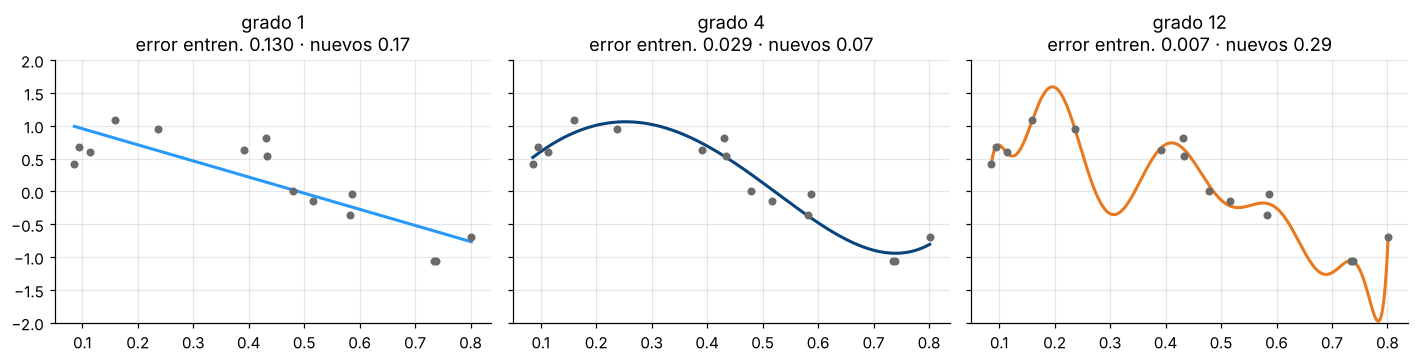

In [3]:
rp = np.random.default_rng(3)
xt = np.sort(rp.uniform(0, 1, 15)); yt = np.sin(2 * np.pi * xt) + rp.normal(0, 0.25, 15)
xv = np.sort(rp.uniform(xt.min(), xt.max(), 200)); yv = np.sin(2 * np.pi * xv) + rp.normal(0, 0.25, 200)
malla = np.linspace(xt.min(), xt.max(), 400)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, grado, col in zip(axes, [1, 4, 12], [CELESTE, AZUL_OSC, NARANJA]):
    p = np.polynomial.polynomial.Polynomial.fit(xt, yt, grado)
    e_tr, e_nu = np.mean((p(xt) - yt) ** 2), np.mean((p(xv) - yv) ** 2)
    ax.scatter(xt, yt, color=GRIS, zorder=3, s=18)
    ax.plot(malla, np.clip(p(malla), -2, 2), color=col, lw=2)
    ax.set_ylim(-2, 2); ax.set_title(f"grado {grado}\nerror entren. {e_tr:.3f} · nuevos {e_nu:.2f}")
plt.tight_layout(); plt.show()

### 1.2 · Sobreajuste a propósito con una red

Paso 2 de la «receta»: primero hay que comprobar que el modelo **puede** aprender. Entrenamos una red grande (3 capas de 256 neuronas, más de 70.000 parámetros) con solo 300 ejemplos.

Parámetros entrenables: 136452


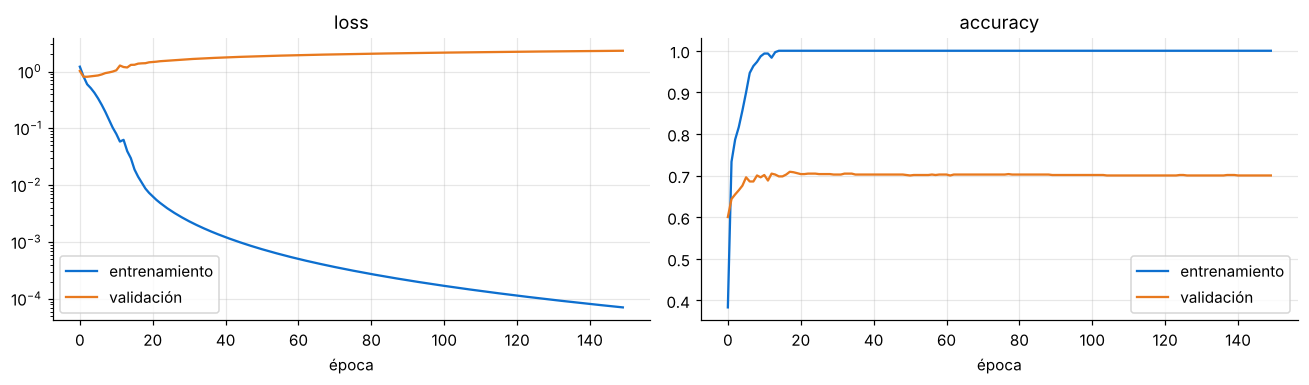

Mejor val_loss: 0.810 en la época 3
Final → accuracy entrenamiento 1.000 · validación 0.700


In [4]:
def construir(l2=0.0, dropout=0.0, batchnorm=False, unidades=(256, 256, 256), lr=1e-3):
    # MLP para el turbofán con regularización opcional.
    norm = layers.Normalization(); norm.adapt(X_train)
    capas = [keras.Input(shape=(14,)), norm]
    for u in unidades:
        reg = regularizers.l2(l2) if l2 else None
        if batchnorm:
            capas += [layers.Dense(u, use_bias=False, kernel_regularizer=reg),
                      layers.BatchNormalization(), layers.Activation("relu")]
        else:
            capas.append(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout:
            capas.append(layers.Dropout(dropout))
    capas.append(layers.Dense(4, activation="softmax"))
    modelo = keras.Sequential(capas)
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


def entrenar(modelo, epocas=150, callbacks=(), Xtr=None, ytr=None):
    keras.utils.set_random_seed(0)
    return modelo.fit(X_train if Xtr is None else Xtr, y_train if ytr is None else ytr,
                      validation_data=(X_val, y_val), epochs=epocas, batch_size=32,
                      callbacks=list(callbacks), verbose=0)


keras.utils.set_random_seed(0)
base = construir()
print("Parámetros entrenables:", base.count_params() - 29)
h_base = entrenar(base)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, k in zip(axes, ["loss", "accuracy"]):
    ax.plot(h_base.history[k], color=AZUL, label="entrenamiento")
    ax.plot(h_base.history["val_" + k], color=NARANJA, label="validación")
    ax.set_title(k); ax.set_xlabel("época"); ax.legend()
axes[0].set_yscale("log"); plt.tight_layout(); plt.show()

h = h_base.history
print(f"Mejor val_loss: {min(h['val_loss']):.3f} en la época {int(np.argmin(h['val_loss'])) + 1}")
print(f"Final → accuracy entrenamiento {h['accuracy'][-1]:.3f} · validación {h['val_accuracy'][-1]:.3f}")

El diagnóstico es claro: la pérdida de entrenamiento sigue bajando hasta casi cero (la red **memoriza** los 300 ejemplos) mientras que la de validación toca fondo muy pronto y después **sube**. Es varianza alta: la rama naranja del diagrama de la sesión.

---
## 2 · Regularización

Entrenamos la **misma red, con los mismos datos y la misma semilla**, añadiendo una técnica cada vez. Así las comparaciones son justas.

In [5]:
parada = lambda paciencia=15: keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia,
                                                             restore_best_weights=True)

experimentos = {
    "Sin regularizar":       (lambda: construir(),                                []),
    "L2 (λ = 1e-2)":         (lambda: construir(l2=1e-2),                         []),
    "Dropout (p = 0,5)":     (lambda: construir(dropout=0.5),                     []),
    "Early stopping":        (lambda: construir(),                                [parada()]),
    "Batch norm":            (lambda: construir(batchnorm=True),                  []),
    "L2 + dropout + parada": (lambda: construir(l2=1e-2, dropout=0.5),            [parada(30)]),
}

historias, modelos, filas = {}, {}, []
for nombre, (fabrica, cbs) in experimentos.items():
    keras.utils.set_random_seed(0)
    m = fabrica()
    t0 = time.perf_counter()
    h = entrenar(m, callbacks=cbs)
    historias[nombre], modelos[nombre] = h, m
    loss_va, acc_va = m.evaluate(X_val, y_val, verbose=0)
    acc_tr = m.evaluate(X_train, y_train, verbose=0)[1]
    filas.append({"técnica": nombre, "épocas": len(h.history["loss"]),
                  "acc. entrenamiento": acc_tr, "acc. validación": acc_va,
                  "brecha": acc_tr - acc_va, "val_loss final": loss_va,
                  "segundos": time.perf_counter() - t0})

tabla = pd.DataFrame(filas).set_index("técnica")
tabla.style.format({"acc. entrenamiento": "{:.3f}", "acc. validación": "{:.3f}", "brecha": "{:.3f}",
                    "val_loss final": "{:.3f}", "segundos": "{:.1f}"})

,épocas,acc. entrenamiento,acc. validación,brecha,val_loss final,segundos
técnica,,,,,,
Sin regularizar,150,1.000,0.700,0.300,2.320,17.2
L2 (λ = 1e-2),150,1.000,0.781,0.219,0.869,17.8
"Dropout (p = 0,5)",150,1.000,0.772,0.228,1.498,18.0
Early stopping,18,0.833,0.655,0.179,0.810,2.7
Batch norm,150,0.997,0.778,0.219,0.961,18.1
L2 + dropout + parada,107,0.983,0.786,0.198,0.907,13.1


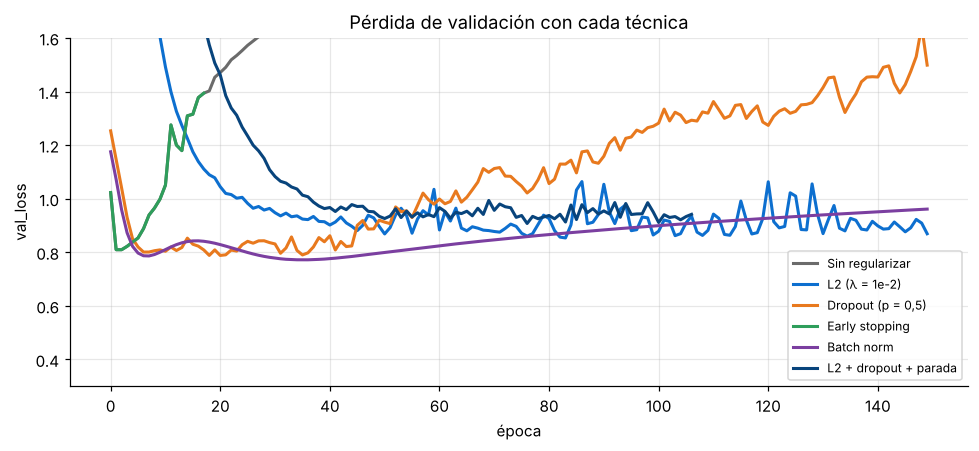

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for (nombre, h), col in zip(historias.items(), COLORES):
    ax.plot(h.history["val_loss"], color=col, lw=2, label=nombre)
ax.set_xlabel("época"); ax.set_ylabel("val_loss"); ax.set_ylim(0.3, 1.6)
ax.set_title("Pérdida de validación con cada técnica"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Cómo leer la tabla** (los comentarios se refieren a esta ejecución, con semilla fija)

- **brecha** = accuracy de entrenamiento − accuracy de validación. Cuanto más pequeña, menos memoriza el modelo.
- **Sin regularizar**: memoriza el 100 % del entrenamiento y su pérdida de validación se dispara, porque cada vez está *más segura* de predicciones erróneas.
- **L2** y **dropout** siguen acertando casi todo el entrenamiento, pero mejoran la validación y contienen la pérdida (L2 especialmente).
- **Early stopping** vigilando `val_loss` para muy pronto y recupera los pesos de la época 3, la de menor pérdida… pero con una accuracy baja. **Pérdida y accuracy no siempre coinciden**: elige bien qué vigilar (`monitor`) y con cuánta paciencia (ejercicio 4).
- **Batch norm** se diseñó para estabilizar y acelerar el entrenamiento, pero aquí también tiene un efecto regularizador apreciable.
- La **combinación** de técnicas da la mejor accuracy de validación.
- Ninguna técnica cierra del todo la brecha: con solo 300 ejemplos, **el límite son los datos** (ejercicio 1).

Los números exactos dependen de la semilla: repite el experimento con otra semilla para ver qué conclusiones se mantienen.

### 2.1 · ¿Qué hace L2 con los pesos?

L2 penaliza los pesos grandes. Comparamos la distribución de los pesos de la primera capa oculta con y sin regularización.

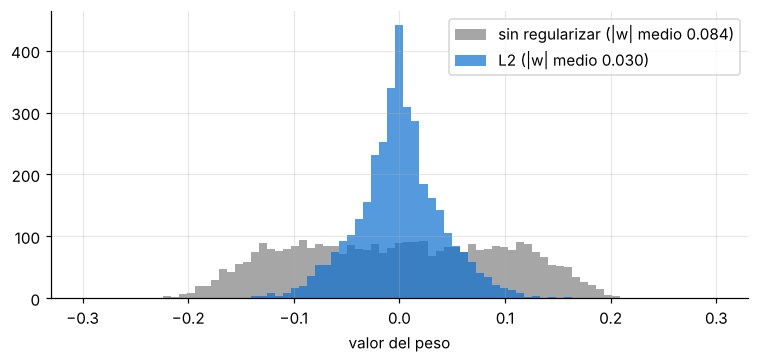

In [7]:
W_base = modelos["Sin regularizar"].layers[1].get_weights()[0].ravel()
W_l2   = modelos["L2 (λ = 1e-2)"].layers[1].get_weights()[0].ravel()

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(-0.3, 0.3, 80)
ax.hist(W_base, bins=bins, alpha=0.6, color=GRIS, label=f"sin regularizar (|w| medio {np.abs(W_base).mean():.3f})")
ax.hist(W_l2, bins=bins, alpha=0.7, color=AZUL, label=f"L2 (|w| medio {np.abs(W_l2).mean():.3f})")
ax.set_xlabel("valor del peso"); ax.legend(); plt.tight_layout(); plt.show()

### 2.2 · Dropout: activo al entrenar, inactivo al predecir

Con `training=True` cada llamada apaga neuronas distintas y la salida cambia; con `training=False` (lo que usan `predict` y `evaluate`) la salida es siempre la misma.

In [8]:
m_drop = modelos["Dropout (p = 0,5)"]
# elegimos un motor dudoso (probabilidad máxima < 0,8) para que se aprecien los cambios
p_inf = m_drop.predict(X_val, verbose=0)
x1 = X_val[[int(np.where(p_inf.max(axis=1) < 0.8)[0][0])]]
print("training=True  (3 llamadas):")
for _ in range(3):
    print("   ", keras.ops.convert_to_numpy(m_drop(x1, training=True))[0].round(3))
print("training=False (3 llamadas):")
for _ in range(3):
    print("   ", keras.ops.convert_to_numpy(m_drop(x1, training=False))[0].round(3))

training=True  (3 llamadas):
    [0.001 0.975 0.017 0.008]
    [0.    0.104 0.    0.896]
    [0.    0.023 0.    0.977]
training=False (3 llamadas):
    [0.    0.531 0.    0.469]
    [0.    0.531 0.    0.469]
    [0.    0.531 0.    0.469]


### 2.3 · Batch normalization: estadísticos del lote frente a medias móviles

Durante el entrenamiento, `BatchNormalization` normaliza con la media y varianza **del lote**. Al mismo tiempo va acumulando **medias móviles**, que son las que usa en inferencia.

In [9]:
bn = [c for c in modelos["Batch norm"].layers if isinstance(c, layers.BatchNormalization)][0]
gamma, beta, media_movil, var_movil = bn.get_weights()
print("Parámetros por neurona: γ, β (entrenables) y media y varianza móviles (no entrenables)")
print("γ (primeras 5):            ", gamma[:5].round(3))
print("β (primeras 5):            ", beta[:5].round(3))
print("media móvil (primeras 5):  ", media_movil[:5].round(3))

Parámetros por neurona: γ, β (entrenables) y media y varianza móviles (no entrenables)
γ (primeras 5):             [1.01  1.001 1.009 1.009 1.004]
β (primeras 5):             [ 0.016  0.001  0.002 -0.008  0.018]
media móvil (primeras 5):   [ 0.001 -0.003 -0.001  0.002  0.007]


> **Ejercicios (partes 1 y 2)**
> 1. Entrena la red sin regularizar con los **4.199 ejemplos** completos (`X_train_full`). ¿Sigue habiendo sobreajuste? Más datos es casi siempre el mejor regularizador.
> 2. Prueba λ = 1e-2 y λ = 1e-5. ¿En qué caso aparece subajuste?
> 3. Prueba dropout con p = 0,1 y p = 0,7.
> 4. Cambia `patience` a 3 y a 50 en *early stopping*. ¿Qué compromiso hay?

---
## 3 · Data augmentation: inspección de paneles

Generamos imágenes sintéticas de 32 × 32 píxeles de un panel con remaches, con o sin **grieta**. La situación es intencionadamente realista:

- **Entrenamiento** (solo 200 imágenes): fotos tomadas en condiciones controladas, con grietas **casi horizontales**, en el **centro** del panel y con **iluminación constante**.
- **Validación**: grietas con **cualquier orientación y posición**, e **iluminación variable**, como ocurrirá en servicio.

> Usamos todavía un MLP (`Flatten` + `Dense`). En la próxima sesión veremos las redes convolucionales, mucho más adecuadas para imágenes.

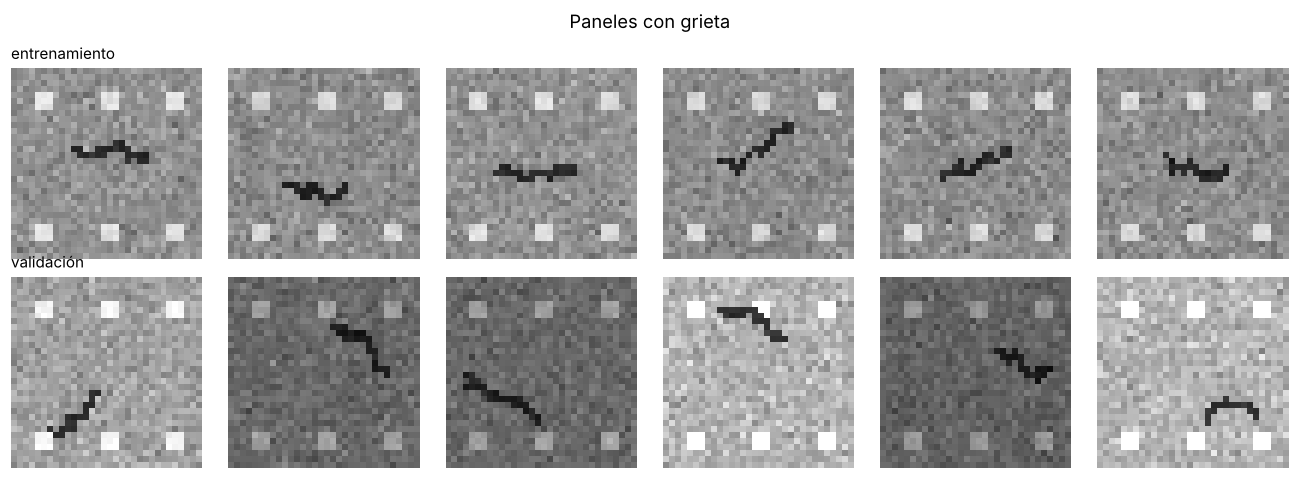

In [10]:
H = 32
remaches = [(5, 5), (5, 16), (5, 27), (27, 5), (27, 16), (27, 27)]
yy, xx = np.ogrid[:H, :H]

def panel(rg, grieta, angulos, brillo, centro):
    img = 0.55 + 0.05 * rg.normal(size=(H, H))
    for r, c in remaches:
        img[(yy - r) ** 2 + (xx - c) ** 2 <= 2] = 0.85
    if grieta:
        ang = np.deg2rad(rg.uniform(*angulos)); L = rg.uniform(8, 14); cx, cy = rg.uniform(*centro, 2)
        t = np.linspace(-L / 2, L / 2, 60); zig = np.cumsum(rg.normal(0, 0.35, 60))
        for px, py in zip(cx + t * np.cos(ang) - zig * np.sin(ang), cy + t * np.sin(ang) + zig * np.cos(ang)):
            if 0 <= round(px) < H and 0 <= round(py) < H:
                img[int(round(py)), int(round(px))] = 0.15
    img = img * rg.uniform(*brillo) + 0.03 * rg.normal(size=img.shape)
    return np.clip(img, 0, 1)

def generar_paneles(n, angulos, brillo, centro, semilla):
    rg = np.random.default_rng(semilla)
    etiquetas = rg.integers(0, 2, n)
    imgs = np.stack([panel(rg, e, angulos, brillo, centro) for e in etiquetas])[..., None]
    return imgs.astype("float32"), etiquetas

Xi_tr, yi_tr = generar_paneles(200, (-10, 10), (0.95, 1.05), (14, 18), semilla=0)
Xi_va, yi_va = generar_paneles(600, (0, 180), (0.6, 1.4), (8, 24), semilla=1)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for fila, (Xs, ys, titulo) in enumerate([(Xi_tr, yi_tr, "entrenamiento"), (Xi_va, yi_va, "validación")]):
    for j, i in enumerate(np.where(ys == 1)[0][:6]):
        axes[fila, j].imshow(Xs[i, ..., 0], cmap="gray", vmin=0, vmax=1); axes[fila, j].axis("off")
    axes[fila, 0].set_title(titulo, loc="left", fontsize=10)
plt.suptitle("Paneles con grieta"); plt.tight_layout(); plt.show()

### 3.1 · Las capas de aumento

Definimos el aumento como un pequeño modelo con capas `Random*`. Veamos qué variantes genera a partir de **una sola** imagen de entrenamiento.

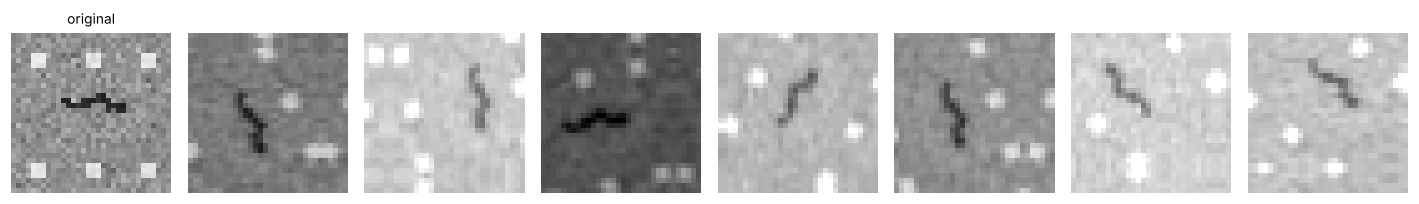

In [11]:
aumento = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5),                      # ±0,5 vueltas: cualquier orientación
    layers.RandomTranslation(0.2, 0.2),              # ±20 % del tamaño
    layers.RandomBrightness(0.3, value_range=(0, 1)),
], name="aumento")

ejemplo = Xi_tr[np.where(yi_tr == 1)[0][0]][None]
fig, axes = plt.subplots(1, 8, figsize=(13, 1.9))
axes[0].imshow(ejemplo[0, ..., 0], cmap="gray", vmin=0, vmax=1); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(keras.ops.convert_to_numpy(aumento(ejemplo, training=True))[0, ..., 0], cmap="gray", vmin=0, vmax=1)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

Las transformaciones elegidas son **físicamente plausibles** para este problema: una grieta sigue siendo una grieta aunque la cámara gire o cambie la luz. En un problema donde la orientación importe (por ejemplo, la dirección de una pista en una imagen aérea), no deberíamos voltear ni rotar.

### 3.2 · Entrenar con y sin aumento

sin aumento  accuracy entrenamiento 1.000 · validación 0.690 · validación media de las 10 últimas épocas 0.688


con aumento  accuracy entrenamiento 0.810 · validación 0.850 · validación media de las 10 últimas épocas 0.890


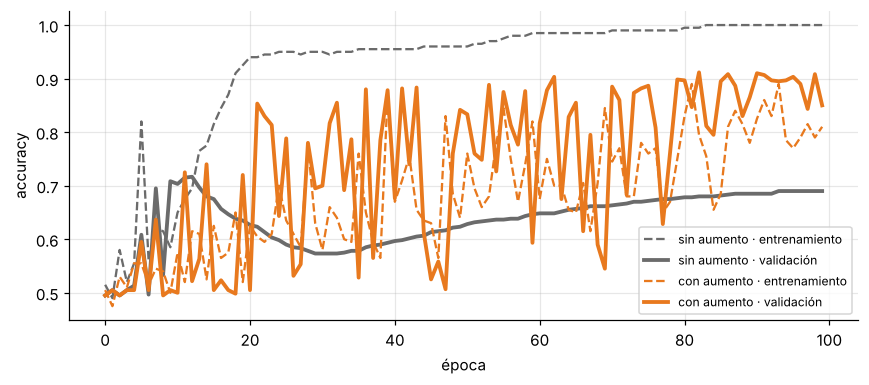

In [12]:
def clasificador_paneles(con_aumento):
    entrada = keras.Input(shape=(H, H, 1))
    x = aumento(entrada) if con_aumento else entrada     # solo actúa durante el entrenamiento
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    salida = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(entrada, salida)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

hist_aug = {}
for nombre, flag in [("sin aumento", False), ("con aumento", True)]:
    keras.utils.set_random_seed(0)
    m = clasificador_paneles(flag)
    hist_aug[nombre] = m.fit(Xi_tr, yi_tr, validation_data=(Xi_va, yi_va), epochs=100, batch_size=32, verbose=0)
    h = hist_aug[nombre].history
    print(f"{nombre:12s} accuracy entrenamiento {h['accuracy'][-1]:.3f} · validación {h['val_accuracy'][-1]:.3f}"
          f" · validación media de las 10 últimas épocas {np.mean(h['val_accuracy'][-10:]):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
for (nombre, hh), col in zip(hist_aug.items(), [GRIS, NARANJA]):
    ax.plot(hh.history["accuracy"], "--", color=col, lw=1.5, label=f"{nombre} · entrenamiento")
    ax.plot(hh.history["val_accuracy"], color=col, lw=2.5, label=f"{nombre} · validación")
ax.set_xlabel("época"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Sin aumento, la red **memoriza** las 200 imágenes de entrenamiento (accuracy cercana a 1) pero falla con grietas en orientaciones y posiciones que nunca vio. Con aumento, la accuracy de entrenamiento es **más baja** (cada época ve imágenes distintas y más difíciles), pero **generaliza mucho mejor**.

La curva de validación con aumento es muy ruidosa: un MLP con solo 200 imágenes de base tiene dificultades para aprender algo invariante a la rotación. Por eso conviene mirar la **media de las últimas épocas** y no un valor suelto. Las redes convolucionales (próxima sesión) resuelven esto mucho mejor.

> Para datos tabulares o de sensores, el equivalente más directo es `layers.GaussianNoise(σ)`, que añade ruido pequeño solo durante el entrenamiento.

> **Ejercicios (parte 3)**
> 1. Quita `RandomRotation` del aumento. ¿Cuánto empeora la validación?
> 2. Genera el conjunto de validación con grietas solo horizontales y centradas (como el de entrenamiento). ¿Sigue ayudando el aumento? ¿Qué conclusión sacas sobre cuándo usarlo?

---
## 4 · Clases desbalanceadas: rodamientos con un 3 % de fallos

Volvemos al problema del rodamiento del cuaderno 1, pero ahora con **fallos raros**, como en la realidad.

In [13]:
rr = np.random.default_rng(5)
n = 12000
horas    = rr.uniform(0, 3000, n)
desgaste = horas / 3000 + rr.normal(0, 0.15, n)
rpm      = rr.normal(12000, 800, n)
vib_rms  = 0.4 + 1.2 * desgaste**2 + 0.00004 * (rpm - 12000) + rr.normal(0, 0.12, n)
curtosis = 3.0 + 2.5 * np.clip(desgaste - 0.5, 0, None) + rr.normal(0, 0.4, n)
temp_C   = 70 + 25 * desgaste + 0.002 * (rpm - 12000) + rr.normal(0, 4, n)
logit = -9.3 + 5.5 * desgaste**2 + 1.1 * (curtosis - 3) + 0.05 * (temp_C - 85)
fallo = (rr.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)

Xr = np.c_[vib_rms, curtosis, temp_C, rpm, horas].astype("float32")
print(f"Proporción de fallos: {fallo.mean():.1%}  ({fallo.sum()} de {n})")

Xr_tmp, Xr_te, yr_tmp, yr_te = train_test_split(Xr, fallo, test_size=0.2, stratify=fallo, random_state=0)
Xr_tr, Xr_va, yr_tr, yr_va = train_test_split(Xr_tmp, yr_tmp, test_size=0.2, stratify=yr_tmp, random_state=0)

Proporción de fallos: 3.0%  (357 de 12000)


### 4.1 · La trampa de la accuracy

In [14]:
pred_trivial = np.zeros_like(yr_te)                  # «siempre sin fallo»
print(f"Modelo trivial → accuracy {np.mean(pred_trivial == yr_te):.1%}  ·  recall de fallos {recall_score(yr_te, pred_trivial):.0%}")

Modelo trivial → accuracy 97.0%  ·  recall de fallos 0%


### 4.2 · Cuatro estrategias

1. **Base**: red normal, umbral 0,5.
2. **`class_weight`**: los errores en la clase minoritaria pesan más en la pérdida.
3. **SMOTE**: generamos ejemplos sintéticos de fallo **solo en el conjunto de entrenamiento**. SMOTE usa distancias entre puntos, así que **estandarizamos antes** (si no, las `rpm`, del orden de 12.000, dominarían la distancia).
4. **Ajuste del umbral**: el modelo base, pero elegimos el umbral que maximiza F1 **en validación**.

In [15]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler().fit(Xr_tr)                       # ajustado solo con entrenamiento
Xs_tr, Xs_va, Xs_te = (escalador.transform(a) for a in (Xr_tr, Xr_va, Xr_te))

def red_binaria():
    m = keras.Sequential([keras.Input(shape=(5,)),
                          layers.Dense(32, activation="relu"), layers.Dense(16, activation="relu"),
                          layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc")])
    return m

def ajustar(Xa, ya, pesos=None):
    keras.utils.set_random_seed(0)
    m = red_binaria()
    m.fit(Xa, ya, validation_data=(Xs_va, yr_va), epochs=40, batch_size=64, class_weight=pesos, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True)])
    return m

# 1 · Base
m_base = ajustar(Xs_tr, yr_tr)

# 2 · class_weight: peso inversamente proporcional a la frecuencia
n0, n1 = np.bincount(yr_tr)
pesos = {0: 1.0, 1: n0 / n1}
m_cw = ajustar(Xs_tr, yr_tr, pesos)
print(f"class_weight = {{0: 1, 1: {n0 / n1:.1f}}}")

# 3 · SMOTE (solo sobre entrenamiento)
X_sm, y_sm = SMOTE(k_neighbors=5, random_state=0).fit_resample(Xs_tr, yr_tr)
print(f"Tras SMOTE: {len(y_sm)} ejemplos de entrenamiento, {y_sm.mean():.0%} de fallos")
m_sm = ajustar(X_sm, y_sm)

# 4 · Umbral óptimo en validación para el modelo base
p_va = m_base.predict(Xs_va, verbose=0).ravel()
umbrales = np.linspace(0.02, 0.9, 89)
f1s = [f1_score(yr_va, (p_va >= u).astype(int), zero_division=0) for u in umbrales]
u_opt = float(umbrales[int(np.argmax(f1s))])
print(f"Umbral que maximiza F1 en validación: {u_opt:.2f}")

class_weight = {0: 1, 1: 32.5}
Tras SMOTE: 14902 ejemplos de entrenamiento, 50% de fallos


Umbral que maximiza F1 en validación: 0.34


In [16]:
def metricas(nombre, modelo, umbral=0.5):
    p = modelo.predict(Xs_te, verbose=0).ravel()
    yp = (p >= umbral).astype(int)
    return {"estrategia": nombre, "umbral": umbral,
            "recall (fallos detectados)": recall_score(yr_te, yp),
            "precisión": precision_score(yr_te, yp, zero_division=0),
            "F1": f1_score(yr_te, yp, zero_division=0),
            "AUC": roc_auc_score(yr_te, p),
            "falsas alarmas": int(((yp == 1) & (yr_te == 0)).sum()),
            "fallos no detectados": int(((yp == 0) & (yr_te == 1)).sum())}

res = pd.DataFrame([metricas("Base", m_base), metricas("class_weight", m_cw),
                    metricas("SMOTE", m_sm), metricas("Base + umbral óptimo", m_base, u_opt)]).set_index("estrategia")
print(f"Conjunto de prueba: {yr_te.sum()} fallos entre {len(yr_te)} rodamientos")
res.style.format({"umbral": "{:.2f}", "recall (fallos detectados)": "{:.2f}", "precisión": "{:.2f}",
                  "F1": "{:.2f}", "AUC": "{:.3f}"})

Conjunto de prueba: 71 fallos entre 2400 rodamientos


,umbral,recall (fallos detectados),precisión,F1,AUC,falsas alarmas,fallos no detectados
estrategia,,,,,,,
Base,0.50,0.52,0.70,0.60,0.972,16,34
class_weight,0.50,0.96,0.19,0.32,0.973,284,3
SMOTE,0.50,0.93,0.17,0.29,0.971,319,5
Base + umbral óptimo,0.34,0.61,0.52,0.56,0.972,40,28


**Cómo interpretarlo** (prueba: 71 fallos entre 2.400 rodamientos)

- El modelo **base** con umbral 0,5 es conservador: da pocas falsas alarmas, pero **se le escapa casi la mitad de los fallos**.
- **`class_weight`** y **SMOTE** desplazan el modelo hacia la clase minoritaria: detectan más del 90 % de los fallos, a cambio de unas 300 falsas alarmas.
- El **AUC** es prácticamente igual en todas: mide la capacidad de *ordenar* rodamientos por riesgo, y esa capacidad no cambia. Lo que cambia es **dónde se corta**.
- Por eso el **umbral** es la palanca más directa: con el mismo modelo base puedes elegir cualquier punto intermedio sin reentrenar. El umbral que maximiza F1 en validación (0,34) da un compromiso intermedio; como en validación solo hay unos 57 fallos, ese umbral es ruidoso y en prueba no mejora el F1 del umbral 0,5. Con tan pocos casos positivos, cualquier métrica de la clase minoritaria tiene mucha incertidumbre.

La elección final es una **decisión de ingeniería**: ¿cuánto cuesta una inspección innecesaria frente a un fallo en vuelo?

> **Ejercicios (parte 4)**
> 1. Aplica SMOTE **antes** de dividir los datos y evalúa. ¿Por qué el resultado sale engañosamente bueno?
> 2. Prueba `keras.losses.BinaryFocalCrossentropy()` como pérdida del modelo base.
> 3. Elige el umbral para garantizar un recall ≥ 0,9 en validación y mira cuántas falsas alarmas produce en prueba.

---
## 5 · Búsqueda de hiperparámetros con Keras Tuner

Volvemos al turbofán con los 300 ejemplos de entrenamiento y buscamos automáticamente:

- número de capas ocultas (1 a 3) y neuronas por capa (16 a 256);
- dropout (0 a 0,5);
- regularización L2 (de 1e-6 a 1e-2, escala logarítmica);
- tasa de aprendizaje (de 1e-4 a 1e-2, escala logarítmica).

Usamos **Hyperband**, que prueba muchas configuraciones con pocas épocas y solo sigue entrenando las prometedoras. La búsqueda tarda unos 4 minutos en una CPU.

In [17]:
import keras_tuner as kt

def construir_hp(hp):
    modelo = keras.Sequential([keras.Input(shape=(14,))])
    norm = layers.Normalization(); norm.adapt(X_train); modelo.add(norm)
    l2 = hp.Float("l2", 1e-6, 1e-2, sampling="log")
    dropout = hp.Float("dropout", 0.0, 0.5, step=0.1)
    for i in range(hp.Int("capas", 1, 3)):
        modelo.add(layers.Dense(hp.Int(f"unidades_{i}", 16, 256, step=16), activation="relu",
                                kernel_regularizer=regularizers.l2(l2)))
        modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(4, activation="softmax"))
    lr = hp.Float("lr", 1e-4, 1e-2, sampling="log")
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modelo

tuner = kt.Hyperband(construir_hp, objective="val_loss", max_epochs=40, factor=3, seed=0,
                     directory="busqueda_kt", project_name="turbofan", overwrite=True)
tuner.search_space_summary()

Search space summary
Default search space size: 5
l2 (Float)
{'default': 1e-06, 'conditions': [], 'min_value': 1e-06, 'max_value': 0.01, 'step': None, 'sampling': 'log'}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
capas (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
unidades_0 (Int)
{'default': None, 'conditions': [], 'min_value': 16, 'max_value': 256, 'step': 16, 'sampling': 'linear'}
lr (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


In [18]:
t0 = time.perf_counter()
tuner.search(X_train, y_train, validation_data=(X_val, y_val), batch_size=32, verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8)])
print(f"Búsqueda terminada en {time.perf_counter() - t0:.0f} s · configuraciones probadas: {len(tuner.oracle.trials)}")

filas = []
for t in tuner.oracle.get_best_trials(num_trials=5):
    v = t.hyperparameters.values
    fila = {"capas": v["capas"]}
    for i in range(3):                                   # neuronas solo de las capas que existen
        fila[f"unidades_{i}"] = v.get(f"unidades_{i}") if i < v["capas"] else None
    fila.update({"dropout": v["dropout"], "l2": f"{v['l2']:.1e}", "lr": f"{v['lr']:.1e}",
                 "épocas": v.get("tuner/epochs"), "val_loss": round(t.score, 4)})
    filas.append(fila)
pd.DataFrame(filas)

Búsqueda terminada en 220 s · configuraciones probadas: 90


,capas,unidades_0,unidades_1,unidades_2,dropout,l2,lr,épocas,val_loss
0,3,80,48.0,224.0,0.3,5.9e-06,4.2e-03,14,0.7172
1,3,80,48.0,224.0,0.3,5.9e-06,4.2e-03,40,0.7228
2,1,208,NaN,NaN,0.0,1.2e-05,2.5e-03,40,0.7324
3,1,144,NaN,NaN,0.1,2.0e-06,9.3e-03,14,0.7403
4,1,208,NaN,NaN,0.0,1.2e-05,2.5e-03,14,0.7416


En la tabla, una misma configuración puede aparecer dos veces: Hyperband la evaluó primero con pocas épocas y, al ser prometedora, siguió entrenándola en la ronda siguiente.

Reentrenamos la mejor configuración con *early stopping* y, **solo ahora, al final**, la evaluamos una única vez en el conjunto de prueba. La comparamos con la red sin regularizar de la parte 1.

In [19]:
mejor_hp = tuner.get_best_hyperparameters(1)[0]
keras.utils.set_random_seed(0)
mejor = construir_hp(mejor_hp)
mejor.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=300, batch_size=32, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])

for nombre, m in [("Red sin regularizar (parte 1)", base), ("Mejor configuración de Keras Tuner", mejor)]:
    loss_te, acc_te = m.evaluate(X_test, y_test, verbose=0)
    print(f"{nombre:36s} prueba → accuracy {acc_te:.3f} · loss {loss_te:.3f}")

Red sin regularizar (parte 1)        prueba → accuracy 0.709 · loss 2.071
Mejor configuración de Keras Tuner   prueba → accuracy 0.749 · loss 0.655


> El conjunto de **prueba** no ha intervenido en ninguna decisión: ni en el entrenamiento, ni en la búsqueda, ni en el *early stopping*. Por eso su resultado es una estimación honesta del rendimiento en servicio.

---
## 6 · Resumen: la receta aplicada

| Paso | Qué hicimos en este cuaderno |
|---|---|
| 1 · Línea base | Modelo trivial en el problema desbalanceado; red sencilla |
| 2 · Sobreajustar | Red de 3 × 256 con 300 ejemplos: memoriza el entrenamiento |
| 3 · Regularizar | L2, dropout, *early stopping*, batch norm y data augmentation |
| 4 · Ajustar | Hyperband con Keras Tuner sobre 5 hiperparámetros |
| 5 · Evaluar | Una sola evaluación en prueba al final |

> **Ejercicio final**
> Aplica la receta completa al problema de regresión de la **carrera de despegue** (cuaderno 1) usando solo 300 ejemplos de entrenamiento. Usa `objective="val_mae"` en Keras Tuner.